In [ ]:
  from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import keras
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os.path

from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten
from keras.layers import Conv2D, MaxPooling2D
from keras import backend as K

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.applications.vgg19 import VGG19
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adamax
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import TensorBoard,EarlyStopping
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2
from tensorflow.keras.applications.inception_v3 import InceptionV3
from keras.applications import Xception
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.layers import Flatten

import sklearn.metrics as metrics

In [ ]:
data = ('/content/drive/MyDrive/Data Repo/AugmentedAlzheimerDataset')

In [ ]:
data = tf.keras.preprocessing.image_dataset_from_directory(data)

Found 33672 files belonging to 4 classes.


In [ ]:
for images, labels in data.map(lambda x, y: (x, y)):
    print(labels)

tf.Tensor([1 1 1 0 1 2 3 2 0 3 2 0 2 2 1 1 0 3 3 2 3 3 0 1 0 1 3 2 2 2 2 1], shape=(32,), dtype=int32)


KeyboardInterrupt: 

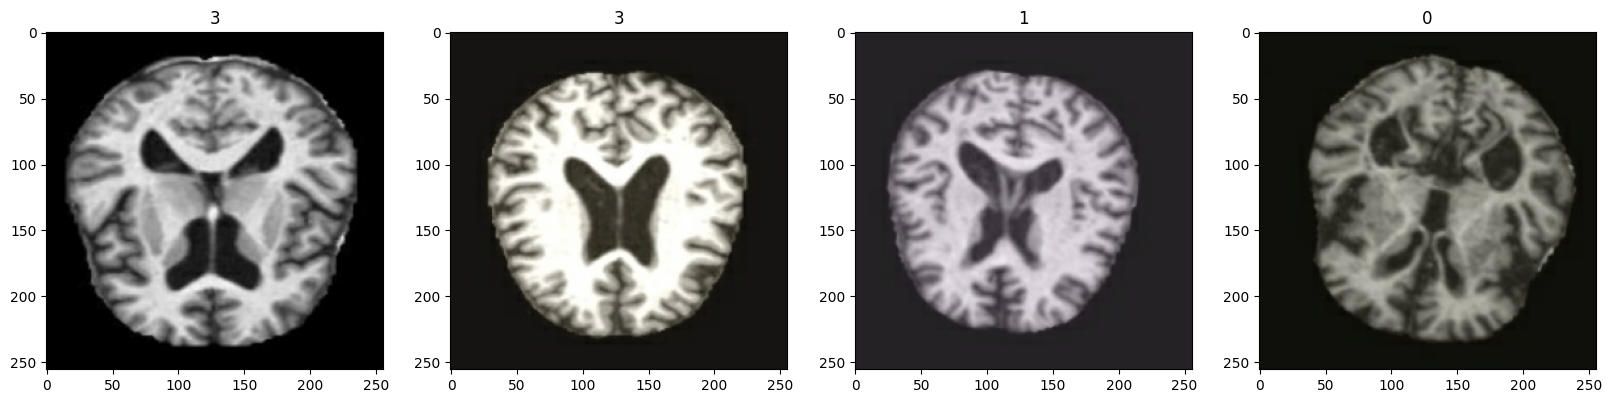

In [ ]:
data_iterator = data.as_numpy_iterator()
batch = data_iterator.next()
batch[0].shape
batch[1]
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    ax[idx].title.set_text(batch[1][idx])

In [ ]:
data = data.map(lambda x,y: (x/255, y)) #This code will create a new dataset where each image is normalized while the labels remain the same.

In [ ]:
data.as_numpy_iterator().next() #used to retrieve the next element from a TensorFlow dataset and convert it to a NumPy array.



(array([[[[0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          ...,
          [0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ]],
 
         [[0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          ...,
          [0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ]],
 
         [[0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          ...,
          [0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ],
          [0.        , 0.        , 0.        ]],
 
         ...,
 
         [[0.        , 0.        , 0.        ],
          [0.     

In [ ]:
# Calculate the initial sizes
original_train_size = int(len(data) * 0.05)  # 70% of data
val_size = int(len(data) * 0.2)  # 20% of data
test_size = len(data) - original_train_size - val_size  # Remaining 10%

# Reduce the training size
reduction_factor = 0.5  # Adjust this factor to control the reduction
train_size = int(original_train_size * reduction_factor)  # Reduced train size

# Adjust the sizes for validation and test sets accordingly
remaining_size = len(data) - train_size
val_size = int(remaining_size * 0.6667)  # 2/3rd of remaining data for validation
test_size = remaining_size - val_size  # Rest for test

# Display the sizes to verify
print(f"Train Size: {train_size}, Validation Size: {val_size}, Test Size: {test_size}")

# Split the data using the new sizes
train = data.take(train_size)
val = data.skip(train_size).take(val_size)
test = data.skip(train_size + val_size).take(test_size)


Train Size: 26, Validation Size: 684, Test Size: 343


In [ ]:
train_size

26

In [ ]:
input_shape = (256, 256, 3)
num_classes=4

In [ ]:
"""model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu', input_shape=input_shape),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(256, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', input_shape=input_shape),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(4, activation='softmax')
])

model.compile(optimizer='SGD',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])"""



model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(num_classes, activation='softmax')

])



In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)                    │ (None, 254, 254, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 127, 127, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 125, 125, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 62, 62, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 60, 60, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 30, 30, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 115200)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │      14,745,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,839,492 (56.61 MB)

 Trainable params: 14,839,492 (56.61 MB)

 Non-trainable params: 0 (0.00 B)

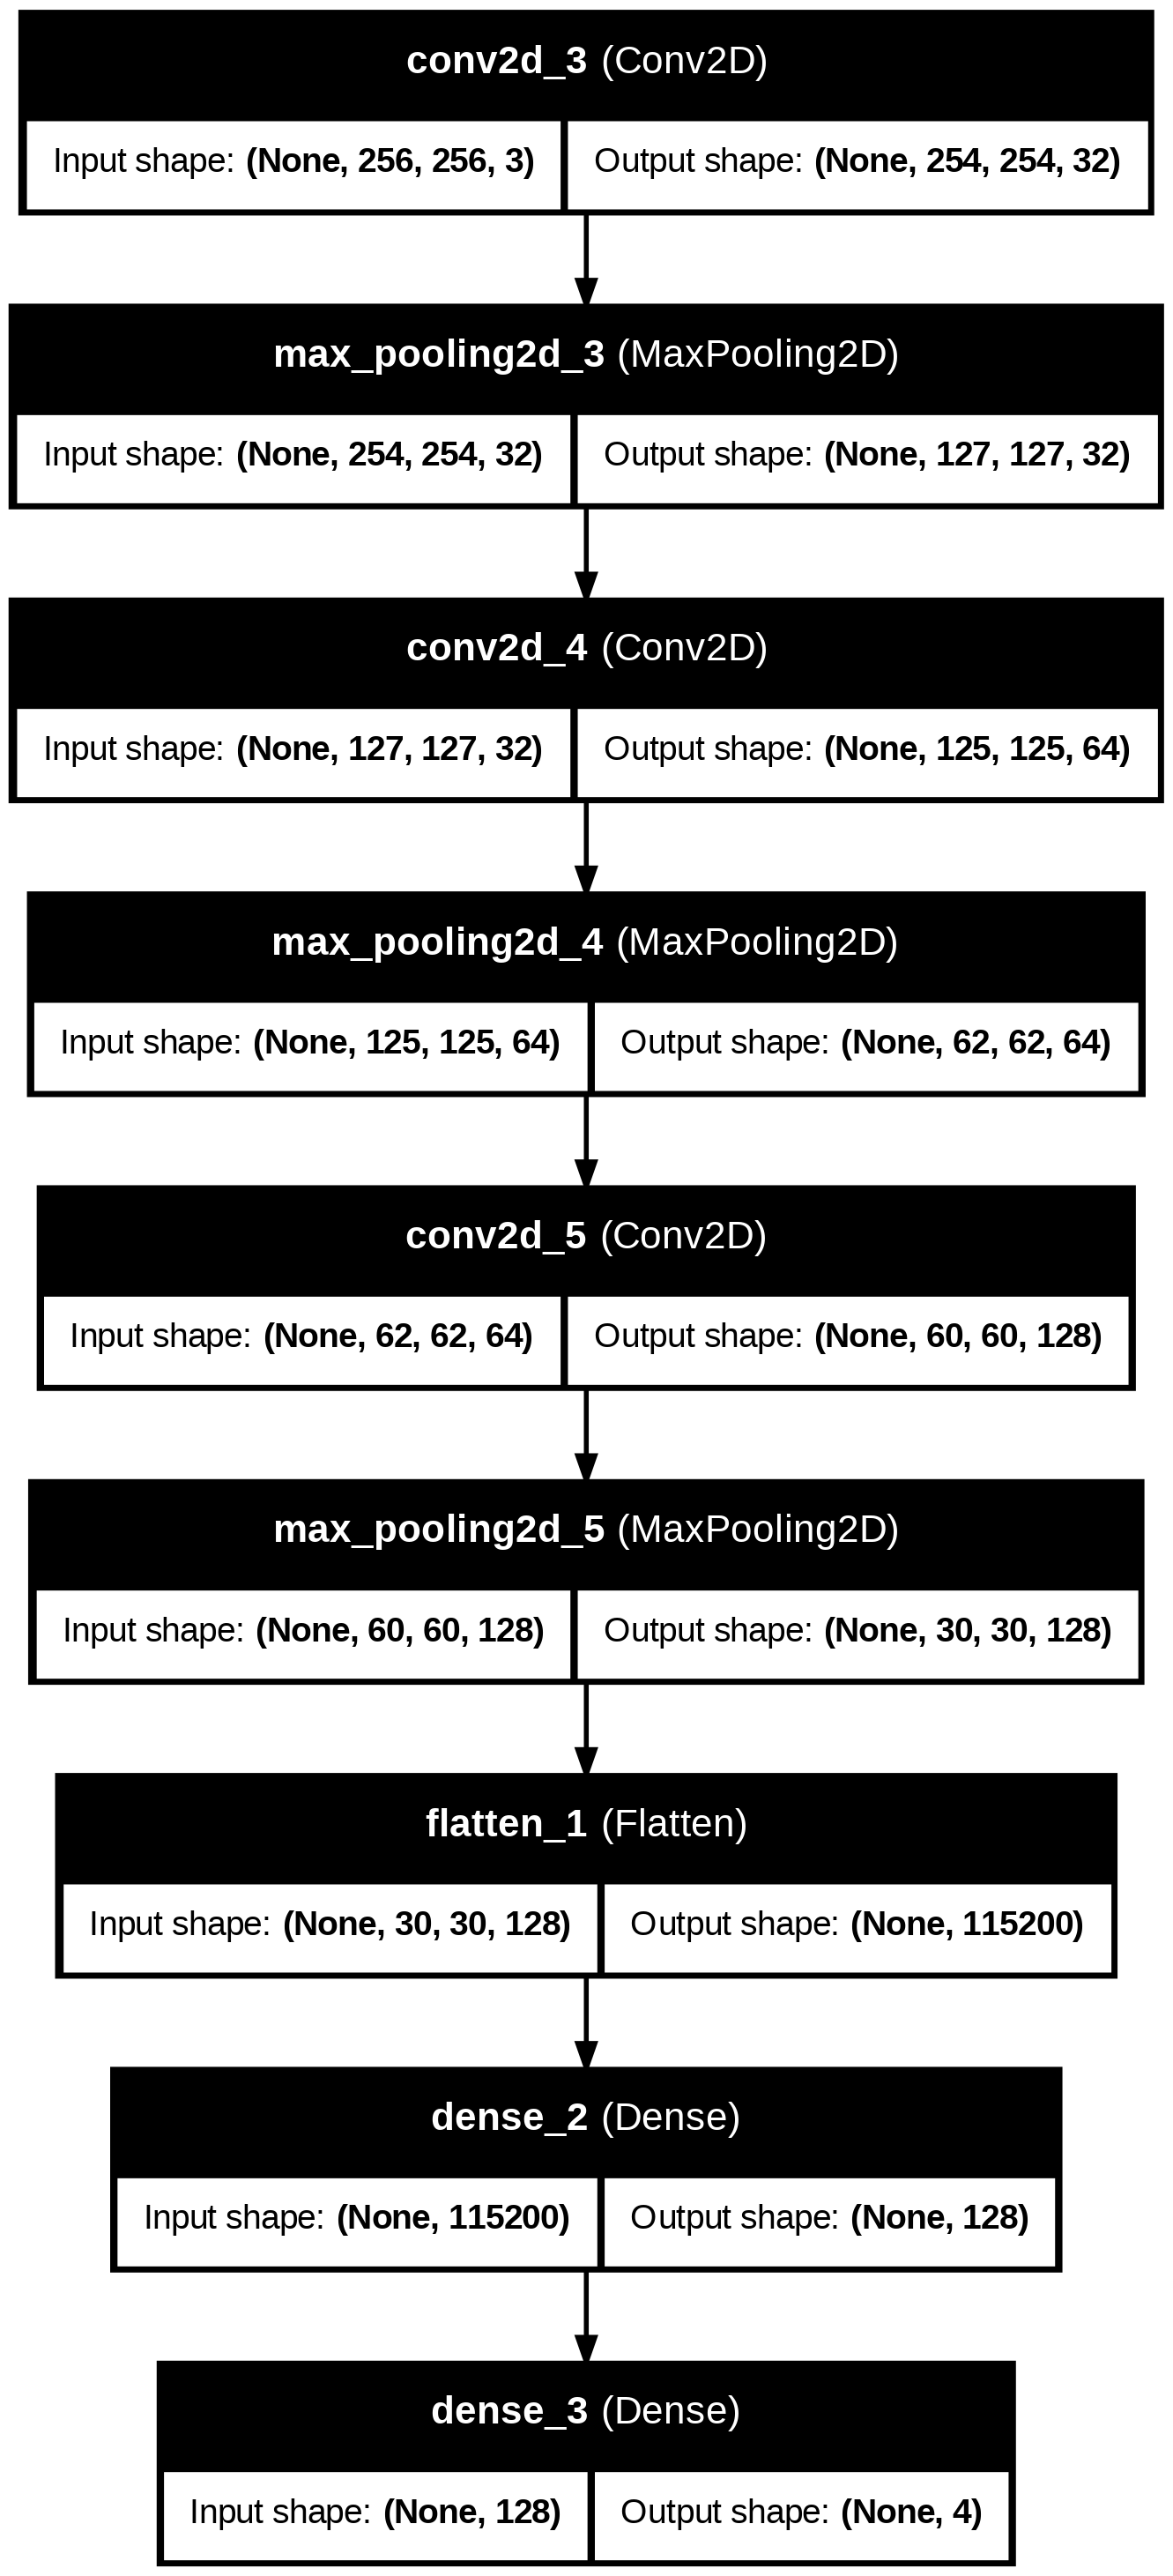

In [ ]:
from keras.utils import plot_model

plot_model(model, to_file='model_plot.png', show_shapes=True, show_layer_names=True)

In [ ]:
num_epochs = 10
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history = model.fit(train, validation_data=val, epochs=num_epochs)

Epoch 1/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.2723 - loss: 2.5769

# PRETRAINED MODEL

In [ ]:
#Create Dataframe with Image Filepaths and Corresponding Alzheimer's Labels


# Define directory paths for different Alzheimer's stages
MildDemented_dir = '/content/drive/MyDrive/Data Repo/AugmentedAlzheimerDataset/MildDemented'
ModerateDemented_dir = '/content/drive/MyDrive/Data Repo/AugmentedAlzheimerDataset/ModerateDemented'
NonDemented_dir = '/content/drive/MyDrive/Data Repo/AugmentedAlzheimerDataset/NonDemented'
VeryMildDemented_dir = '/content/drive/MyDrive/Data Repo/AugmentedAlzheimerDataset/VeryMildDemented'

# Create empty lists to store filepaths and corresponding labels
filepaths = []
labels = []

# Combine directory paths and class labels into a list of tuples
dict_list = [MildDemented_dir, ModerateDemented_dir, NonDemented_dir, VeryMildDemented_dir]
class_labels = ['Mild Demented', 'Moderate Demented', 'Non Demented', 'Very MildDemented']

# Iterate through directory paths and their corresponding labels
for i, j in enumerate(dict_list):
    flist = os.listdir(j)
    for f in flist:
        fpath = os.path.join(j, f)
        filepaths.append(fpath)
        labels.append(class_labels[i])
# Create pandas Series for filepaths and labels
Fseries = pd.Series(filepaths, name="filepaths")
Lseries = pd.Series(labels, name="labels")
# Combine the Series into a DataFrame
Alzheimer_data = pd.concat([Fseries, Lseries], axis=1)
Alzheimer_df = pd.DataFrame(Alzheimer_data)
print(Alzheimer_df.head())
print(Alzheimer_df["labels"].value_counts())

                                           filepaths         labels
0  /content/drive/MyDrive/Data Repo/AugmentedAlzh...  Mild Demented
1  /content/drive/MyDrive/Data Repo/AugmentedAlzh...  Mild Demented
2  /content/drive/MyDrive/Data Repo/AugmentedAlzh...  Mild Demented
3  /content/drive/MyDrive/Data Repo/AugmentedAlzh...  Mild Demented
4  /content/drive/MyDrive/Data Repo/AugmentedAlzh...  Mild Demented
labels
Non Demented         9288
Mild Demented        8960
Very MildDemented    8960
Moderate Demented    6464
Name: count, dtype: int64


In [ ]:
train_images, test_images = train_test_split(Alzheimer_df, test_size=0.3, random_state=42)
train_set, val_set = train_test_split(Alzheimer_df, test_size=0.2, random_state=42)

In [ ]:
print(train_set.shape)
print(test_images.shape)
print(val_set.shape)
print(train_images.shape)

(26937, 2)
(10102, 2)
(6735, 2)
(23570, 2)


In [ ]:
Alzheimer_df.shape

(33672, 2)

In [ ]:
"""image_gen = ImageDataGenerator(preprocessing_function= tf.keras.applications.mobilenet_v2.preprocess_input)
train = image_gen.flow_from_dataframe(dataframe= train_set,x_col="filepaths",y_col="labels",
                                      target_size=(244,244),
                                      color_mode='rgb',
                                      class_mode="categorical", #used for Sequential Model
                                      batch_size=32,
                                      shuffle=False            #do not shuffle data
                                     )
test = image_gen.flow_from_dataframe(dataframe= test_images,x_col="filepaths", y_col="labels",
                                     target_size=(244,244),
                                     color_mode='rgb',
                                     class_mode="categorical",
                                     batch_size=32,
                                     shuffle= False
                                    )
val = image_gen.flow_from_dataframe(dataframe= val_set,x_col="filepaths", y_col="labels",
                                    target_size=(244,244),
                                    color_mode= 'rgb',
                                    class_mode="categorical",
                                    batch_size=32,
                                    shuffle=False
                                   )
# Convert DataFrameIterators to TensorFlow Datasets
train_dataset = tf.data.Dataset.from_generator(
    lambda: train,
    output_types=(tf.float32, tf.float32),
    output_shapes=([None, 244, 244, 3], [None, 4])
)

test_dataset = tf.data.Dataset.from_generator(
    lambda: test,
    output_types=(tf.float32, tf.float32),
    output_shapes=([None, 244, 244, 3], [None, 4])
)

val_dataset = tf.data.Dataset.from_generator(
    lambda: val,
    output_types=(tf.float32, tf.float32),
    output_shapes=([None, 244, 244, 3], [None, 4])
)


train_batches = tf.data.experimental.cardinality(train_dataset)
train_dataset = train_dataset.take(train_batches // 20) # Comment out this line to use the full dataset

val_batches = tf.data.experimental.cardinality(val_dataset)
test_dataset = val_dataset.take(val_batches // 20)
validation_dataset = val_dataset.skip(val_batches // 20)

val_batches = tf.data.experimental.cardinality(val_dataset)
validation_dataset = validation_dataset.take(val_batches // 20)  # Comment out this line to use the full dataset"""



# Specify the number of samples we want to use from each dataset
num_samples = 1000  # Adjust this number as needed

# Sample the dataframes to reduce the number of images used
train_set_sampled = train_set.sample(n=num_samples, random_state=42)
test_images_sampled = test_images.sample(n=num_samples, random_state=42)
val_set_sampled = val_set.sample(n=num_samples, random_state=42)

# Create the ImageDataGenerator
image_gen = ImageDataGenerator(preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input)

# Create the training data generator
train = image_gen.flow_from_dataframe(
    dataframe=train_set_sampled,
    x_col="filepaths",
    y_col="labels",
    target_size=(256, 256),
    color_mode='rgb',
    class_mode="categorical",  # Used for Sequential Model
    batch_size=32,
    shuffle=False  # Do not shuffle data
)

# Create the testing data generator
test = image_gen.flow_from_dataframe(
    dataframe=test_images_sampled,
    x_col="filepaths",
    y_col="labels",
    target_size=(256, 256),
    color_mode='rgb',
    class_mode="categorical",
    batch_size=32,
    shuffle=False
)

# Create the validation data generator
val = image_gen.flow_from_dataframe(
    dataframe=val_set_sampled,
    x_col="filepaths",
    y_col="labels",
    target_size=(256, 256),
    color_mode='rgb',
    class_mode="categorical",
    batch_size=32,
    shuffle=False
)




Found 1000 validated image filenames belonging to 4 classes.
Found 1000 validated image filenames belonging to 4 classes.
Found 1000 validated image filenames belonging to 4 classes.


In [ ]:
classes=list(train.class_indices.keys())
print (classes)

['Mild Demented', 'Moderate Demented', 'Non Demented', 'Very MildDemented']


In [ ]:
def show_images(image_gen):
    test_dict = test.class_indices
    classes = list(test_dict.keys())
    images, labels=next(image_gen) # get a sample batch from the generator
    plt.figure(figsize=(20,20))
    length = len(labels)
    if length<25:
        r=length
    else:
        r=25
    for i in range(r):
        plt.subplot(5,5,i+1)
        image=(images[i]+1)/2 #scale images between 0 and 1
        plt.imshow(image)
        index=np.argmax(labels[i])
        class_name=classes[index]
        plt.title(class_name, color="green",fontsize=16)
        plt.axis('off')
    plt.show()

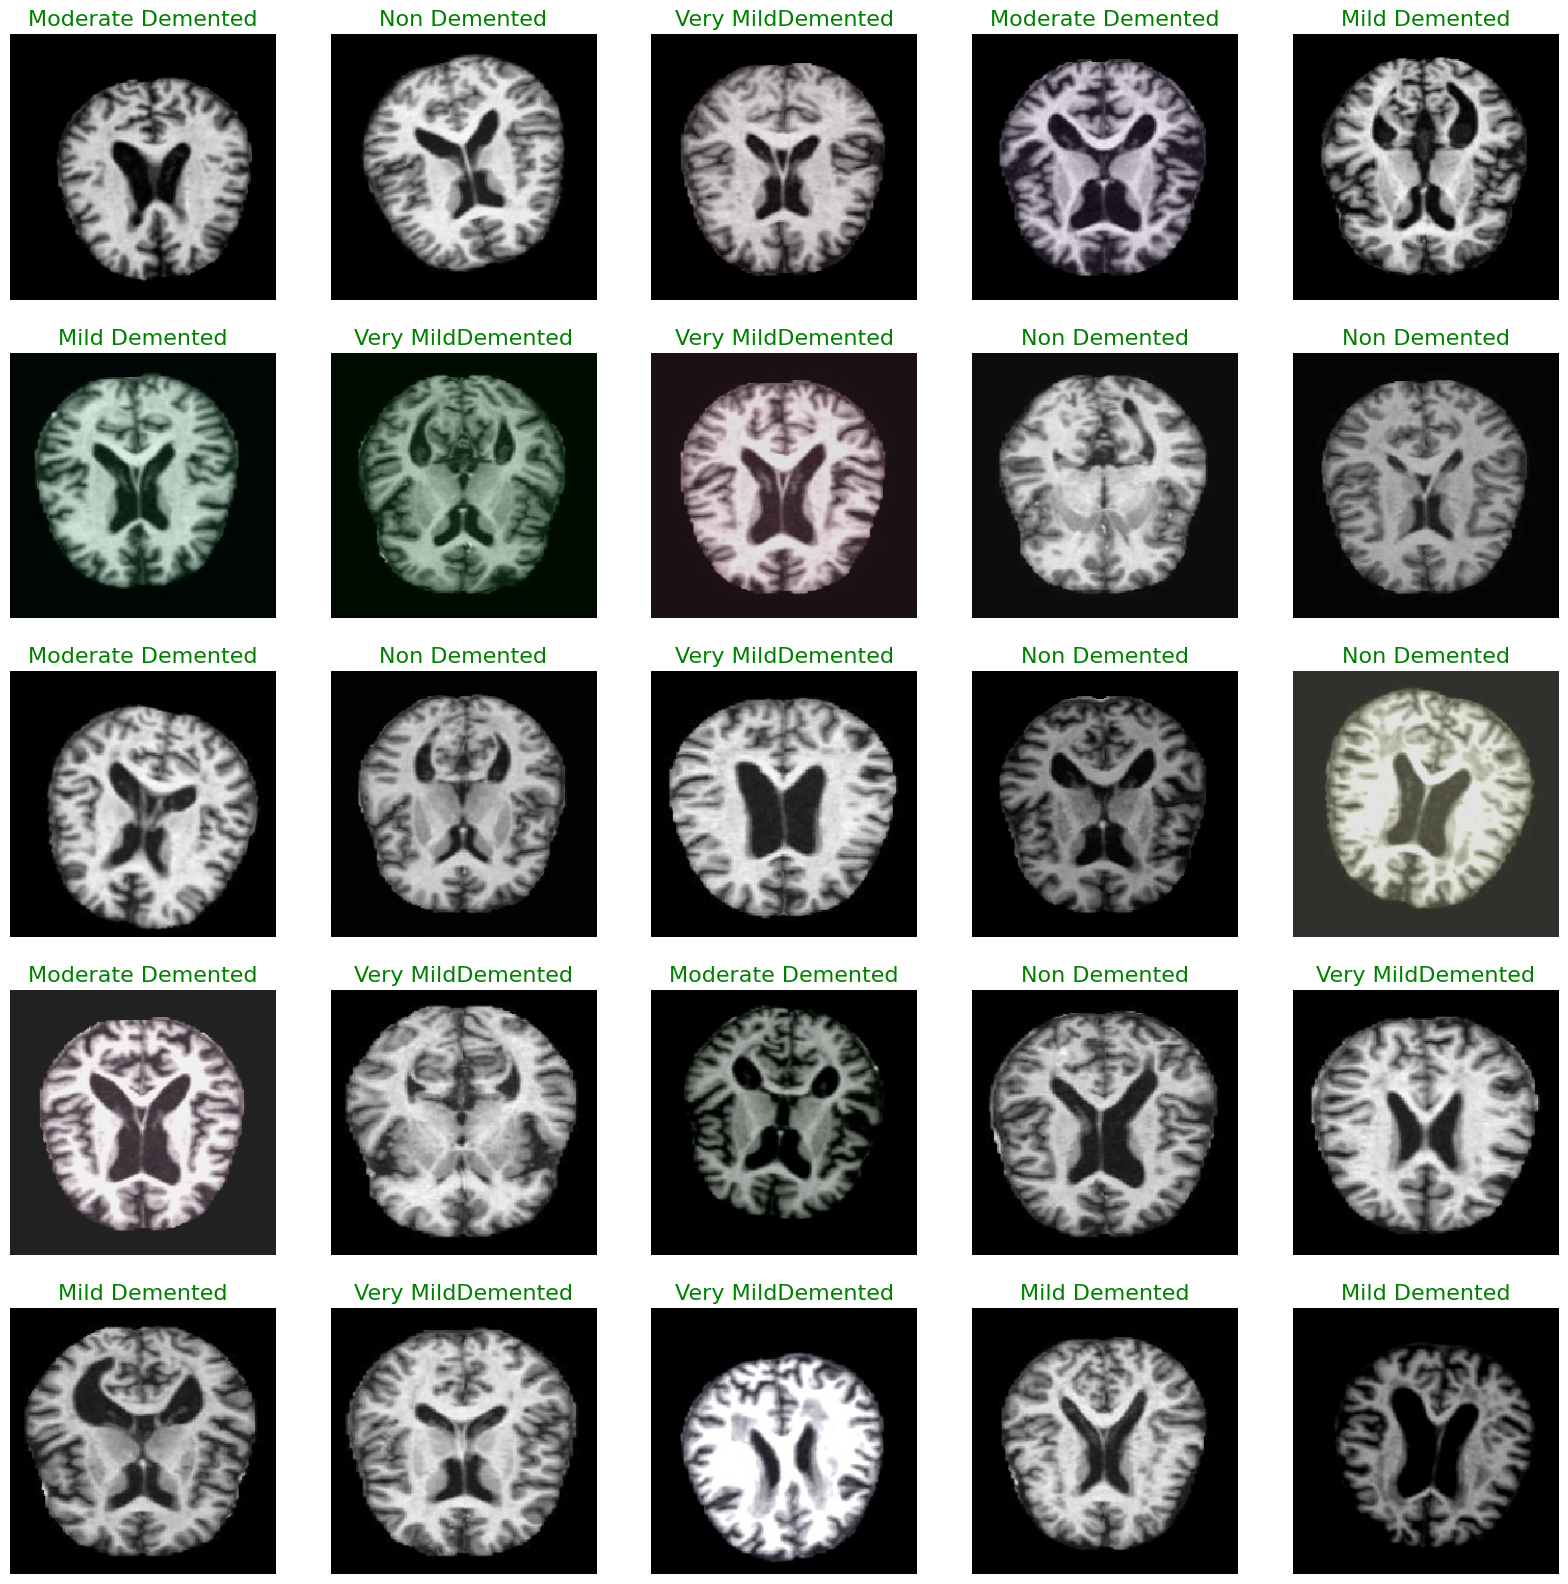

In [ ]:
show_images(train)

In [ ]:
from tensorflow.keras import layers

IMAGE_SIZE = 224
resize_and_rescale = tf.keras.Sequential([
  layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
  layers.Rescaling(1./224),
])

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze the base model

# Custom CNN layers
inputs = Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)

outputs = Dense(3, activation='softmax')(x)

model = Model(inputs, outputs)

learning = 0.0001
init_epochs = 10

model.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=learning),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='sparse_categorical_accuracy')])

model.summary()

<ipython-input-71-10012e7d6f6b>:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  model2.add(MobileNetV2(include_top=False, pooling='avg', weights='imagenet', input_shape=(256, 256, 3)))# Added input shape


Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 1280)                │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_14 (Flatten)                 │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_9                │ (None, 1280)                │           5,120 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 4)                   │           5,124 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,268,228 (8.65 MB)

 Trainable params: 7,684 (30.02 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

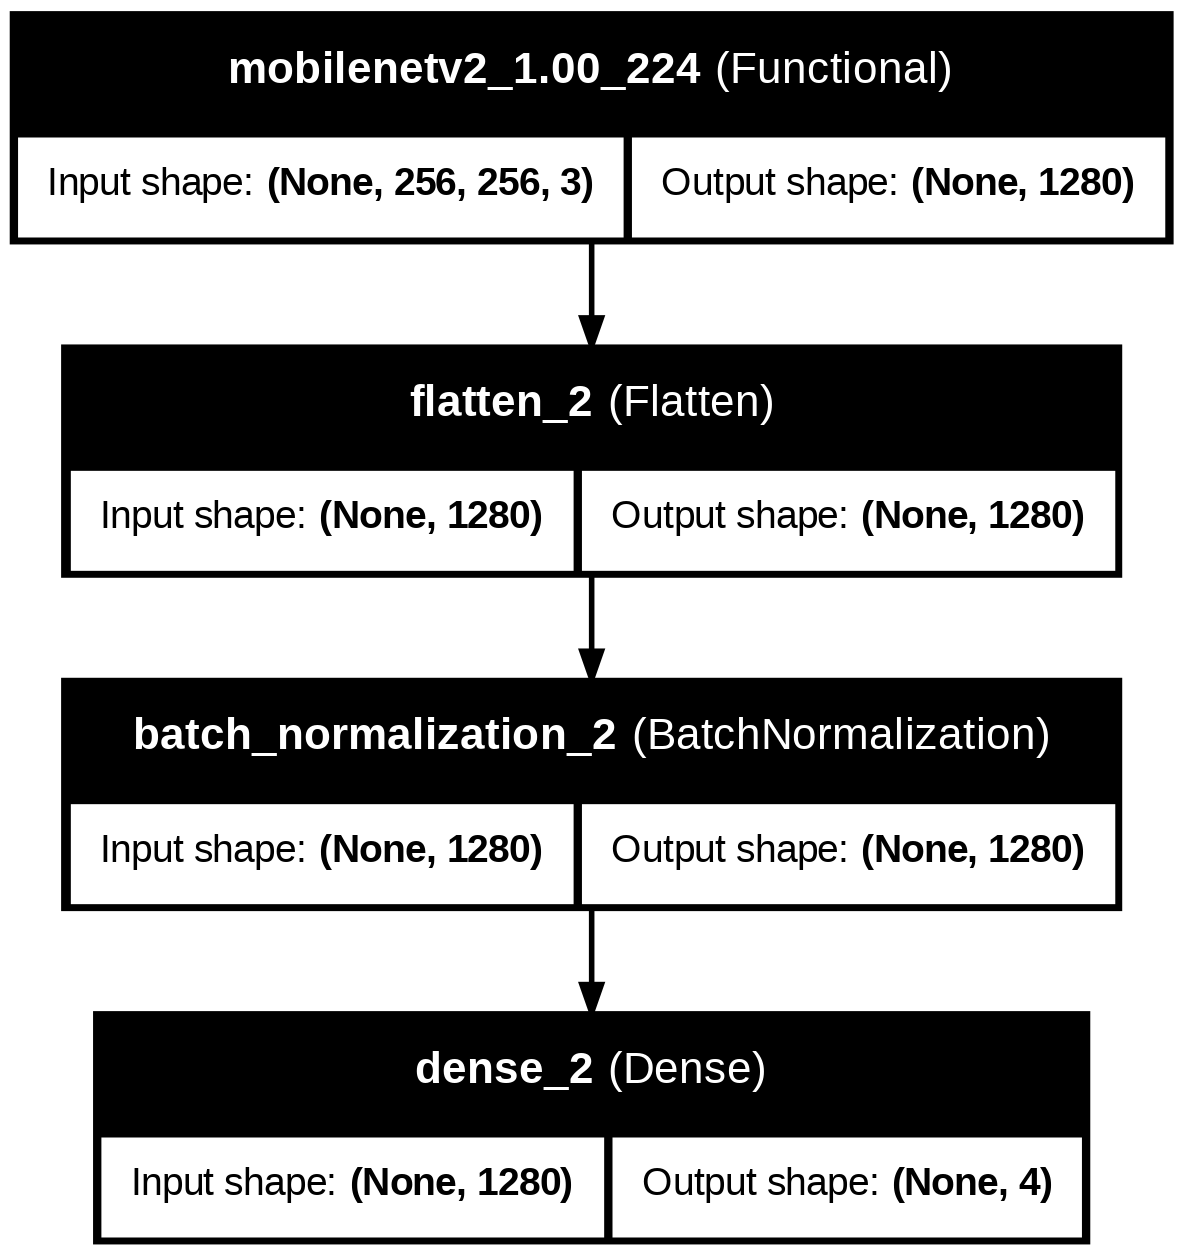

In [ ]:
from keras.utils import plot_model

plot_model(model2, to_file='model_plot.png', show_shapes=True, show_layer_names=True)


In [ ]:
history = model2.fit(
    train,
    epochs=10,
    validation_data=val,
    callbacks = [early_stopping],
    validation_freq=1
)

Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 822s 24s/step - accuracy: 0.3288 - loss: 1.6440 - val_accuracy: 0.4660 - val_loss: 1.1996
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 155s 5s/step - accuracy: 0.5897 - loss: 0.9803 - val_accuracy: 0.5420 - val_loss: 1.0948
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 188s 4s/step - accuracy: 0.6586 - loss: 0.8289 - val_accuracy: 0.5590 - val_loss: 1.0563
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 142s 4s/step - accuracy: 0.7498 - loss: 0.6641 - val_accuracy: 0.5620 - val_loss: 1.0248
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 204s 5s/step - accuracy: 0.8069 - loss: 0.5669 - val_accuracy: 0.5770 - val_loss: 0.9764
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 162s 5s/step - accuracy: 0.8214 - loss: 0.5269 - val_accuracy: 0.5980 - val_loss: 0.9463
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 173s 4s/step - accuracy: 0.8575 - loss: 0.4536 - val_accuracy: 0.6220 - val_loss: 0.9219
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 166s 5s/step - accuracy: 0.8497 - loss: 0.4510 - val_accuracy: 0.6260 - 

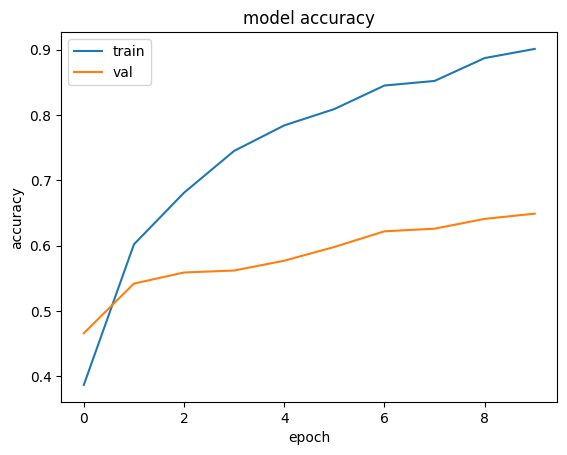

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

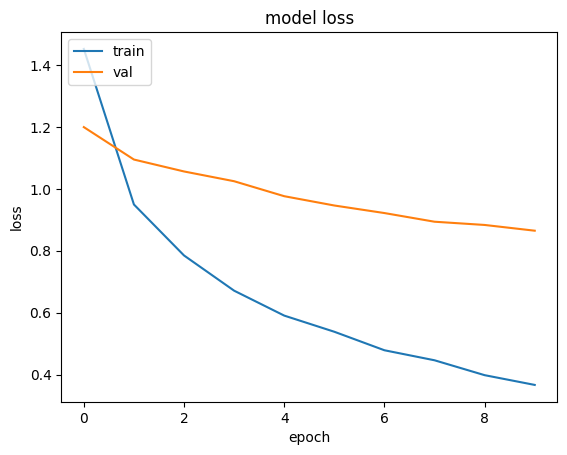

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()


32/32 ━━━━━━━━━━━━━━━━━━━━ 370s 12s/step


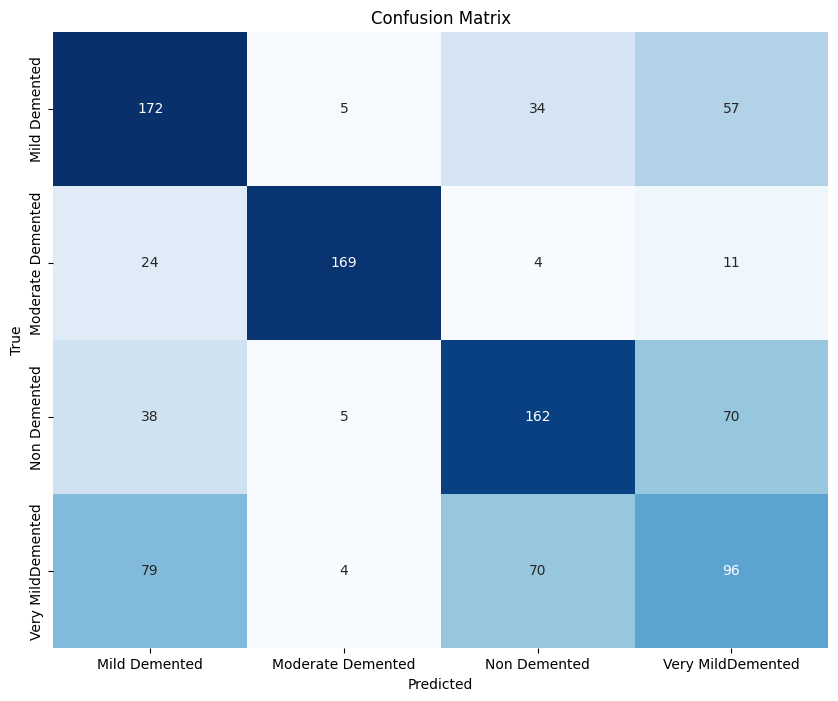

In [ ]:

from sklearn.metrics import confusion_matrix
import seaborn as sns


y_true = test.classes
y_pred = model2.predict(test)
y_pred_classes = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, cbar=False)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()
